# 1. Environnement et données

**Projet** : agent conversationnel RAG sur les documents d'informations clés (DIC) du département ALM d'un assureur vie.
**Contraintes** : modèles *open weights* exécutés localement (aucune API tierce), réponses **sourcées**, **mémoire conversationnelle**, base vectorielle **locale** (ChromaDB), et **F1 BERTScore > 60 %** sur le dataset d'évaluation.

Environnement : le Cloud Sandbox du projet initial (2 GPU 24 Gio, 6 h) est remplacé par le **DGX Spark** (GPU NVIDIA GB10) + JupyterLab, comme pour le projet *assistant de service client*.

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.insert(0, os.path.abspath(".."))
import pandas as pd, numpy as np
pd.set_option("display.max_colwidth", 110, "display.width", 200, "display.max_columns", 30)

## 1.1 Machine, LLM local et versions

In [2]:
import subprocess, torch, importlib.metadata as md
print(subprocess.run(["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv"], capture_output=True, text=True).stdout)
print("torch", torch.__version__, "| CUDA disponible :", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0))
from rag.llm import model_name
from rag.config import LLM_BASE_URL, EMBED_MODEL, RERANK_MODEL
print("LLM open weights (vLLM, local) :", model_name(), "@", LLM_BASE_URL)
print("Embeddings :", EMBED_MODEL, "| Reranker :", RERANK_MODEL)
for p in ["langchain", "langchain-core", "langchain-openai", "langchain-chroma", "chromadb", "sentence-transformers", "pymupdf", "bert-score", "transformers"]:
    print(f"{p:24s}", md.version(p))

name, driver_version
NVIDIA GB10, 580.178.04

torch 2.14.1+cu130 | CUDA disponible : True | NVIDIA GB10


LLM open weights (vLLM, local) : unsloth/Qwen3.8-27B-NVFP4 @ http://localhost:8000/v1
Embeddings : BAAI/bge-m3 | Reranker : BAAI/bge-reranker-v2-m3
langchain                1.4.5
langchain-core           1.6.10
langchain-openai         1.7.1
langchain-chroma         1.1.0
chromadb                 1.5.9
sentence-transformers    6.1.0
pymupdf                  1.28.2
bert-score               0.3.13
transformers             5.19.0


## 1.2 Les 63 DIC
Le parsing utilise **PyMuPDF** (les DIC sont des PDF natifs à 2 colonnes, sans scan : aucun OCR nécessaire). Le catalogue *produit / société de gestion / ISIN* de chaque document a été extrait par le LLM local (prompt `04_extraction_metadata_document.md`).

In [3]:
from rag.config import CATALOG_PATH
from rag.ingest import list_pdfs, load_pdf
cat = json.loads(CATALOG_PATH.read_text(encoding="utf-8"))
rows = []
for p in list_pdfs():
    pages = load_pdf(p); txt = "\n".join(t for _, t in pages)
    rows.append({"fichier": p.name, "pages": len(pages), "caractères": len(txt), **{k: cat[p.name][k] for k in ("produit", "societe_gestion", "isin")}})
inv = pd.DataFrame(rows)
print(f"{len(inv)} DIC | {inv.pages.sum()} pages | {inv['caractères'].sum():,} caractères | {inv["isin"].notna().sum()} avec ISIN identifié")
inv.sample(8, random_state=0)

63 DIC | 175 pages | 894,373 caractères | 59 avec ISIN identifié


,fichier,pages,caractères,produit,societe_gestion,isin
43,KIDPRIIPs_448030_79626_FRA_FRA_20240101.pdf,3,13812,Amundi S&P 500 II UCITS ETF EUR Hedged Acc,Amundi Luxembourg S.A.,LU0959211326
49,KIDPRIIPs_69463_FRA_FRA_20230928.pdf,3,16920,AMUNDI PEA S&P 500 ESG UCITS ETF- Acc,AMUNDI,NaN
62,pictet_2.pdf,2,11736,Pictet - Global Environmental Opportunities P EUR,Pictet Asset Management (Europe) S.A.,LU0503631714
51,ODDO BHF.pdf,2,12480,ODDO BHF Avenir Part CR-EUR,ODDO BHF Asset Management SAS,FR0000989899
32,KIDPRIIPs_434452_79919_FRA_FRA_20231011.pdf,3,15048,AMUNDI EURO STOXX 50 II UCITS ETF USD Hedged Acc,Amundi Asset Management,FR0012399806
34,KIDPRIIPs_434807_79593_FRA_FRA_20231011.pdf,3,14737,Amundi MSCI World II UCITS ETF EUR Hedged Dist,Amundi Asset Management,FR0011660927
29,KIDPRIIPs_408300_85746_FRA_FRA_20230914.pdf,3,14427,AMUNDI S&P 500 ESG UCITS ETF - Acc EUR HEDGED,Amundi Ireland Limited,IE00058MW3M8
46,KIDPRIIPs_448123_79630_FRA_FRA_20240101.pdf,3,13615,Amundi S&P 500 II UCITS ETF USD Dist,Amundi Luxembourg S.A.,LU0496786657


In [4]:
print(inv.societe_gestion.str.replace(r"\s*\(.*\)", "", regex=True).value_counts().head(8).to_string())
print("\nPages par DIC :", inv.pages.value_counts().sort_index().to_dict())

societe_gestion
Amundi Luxembourg S.A.            26
SG 29 HAUSSMANN                    7
Amundi Asset Management            7
Amundi Ireland Limited             6
Pictet Asset Management S.A.       2
FIL Investment Management S.A.     2
Société Générale Gestion           2
Allianz Global Investors GmbH      1

Pages par DIC : {2: 14, 3: 49}


Exemple de contenu (indicateur de risque d'un DIC, tel que fourni dans l'énoncé) :

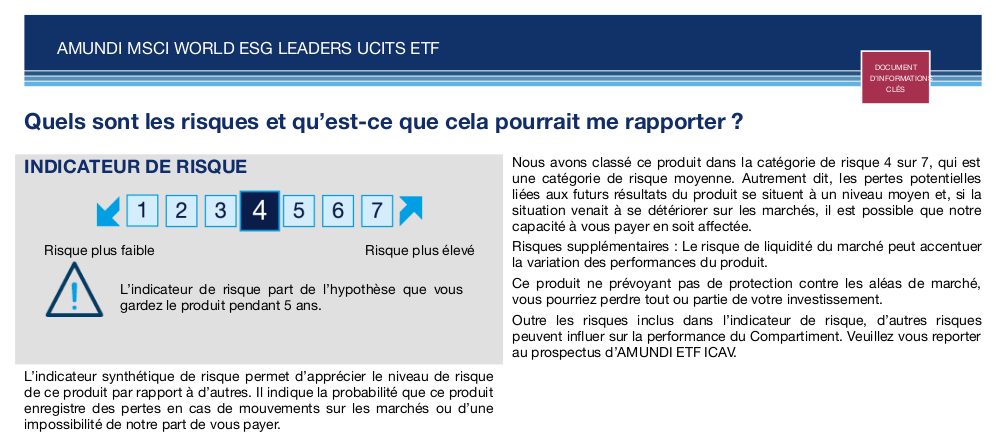

In [5]:
from IPython.display import Image
Image("../docs/exemple_dic_indicateur_risque.png", width=800)

## 1.3 Nettoyage du texte extrait
Les DIC contiennent des ligatures (ﬁ, ﬀ, ﬂ), des espaces insécables, des césures et des caractères parasites qui dégradent embeddings et réponses ; `clean_text` les normalise.

In [6]:
import pymupdf
from rag.ingest import clean_text
for p in list_pdfs():
    raw = pymupdf.open(p)[0].get_text()
    if "\ufb01" in raw: break
i = raw.index("\ufb01")
snippet = raw[max(0, i - 60): i + 80]
print("BRUT    :", repr(snippet))
print("NETTOYÉ :", repr(clean_text(snippet)))

BRUT    : 's vous sont fournies conformément à une obligation légale, aﬁn de vous aider à comprendre en quoi consiste ce\nproduit et quels risques, coût'
NETTOYÉ : 's vous sont fournies conformément à une obligation légale, afin de vous aider à comprendre en quoi consiste ce\nproduit et quels risques, coût'


## 1.4 Dataset d'évaluation
`corpus.json` (chunks), `queries.json`, `relevant_docs.json`, `answers.json`, `errors.json` — tous joints par l'`uuid` de la question.

In [7]:
from rag.evaluation import load_eval
ev = load_eval()
print({k: len(v) for k, v in ev.items()})
print("clés identiques (queries / relevant_docs / answers) :", set(ev["queries"]) == set(ev["relevant_docs"]) == set(ev["answers"]))
print("passages pertinents par question :", pd.Series([len(v) for v in ev["relevant_docs"].values()]).value_counts().to_dict())
df = pd.DataFrame({"question": ev["queries"], "reference": ev["answers"]})
df["mots_reference"] = df.reference.str.split().str.len()
print("\nLongueur des réponses de référence (mots) :"); print(df.mots_reference.describe().round(1).to_string())
print("\nLongueur des chunks du corpus (caractères) :"); print(pd.Series([len(t) for t in ev["corpus"].values()]).describe().round(0).to_string())

{'corpus': 250, 'queries': 619, 'relevant_docs': 619, 'answers': 619, 'errors': 0}
clés identiques (queries / relevant_docs / answers) : True
passages pertinents par question : {1: 619}

Longueur des réponses de référence (mots) :
count    619.0
mean      15.2
std       12.7
min        1.0
25%        4.0
50%       13.0
75%       22.0
max       70.0

Longueur des chunks du corpus (caractères) :
count     250.0
mean      715.0
std       186.0
min       143.0
25%       711.0
50%       752.0
75%       778.0
max      2473.0


### Points d'attention sur le dataset (impact direct sur le score)
1. **Réponses de référence courtes** (médiane 13 mots) : un assistant bavard est pénalisé par BERTScore → le prompt impose des réponses concises.
2. **Questions génériques** : beaucoup de questions ne nomment aucun produit (« quel est l'indicateur de risque de ce produit ? ») alors que 63 DIC répondent différemment. La bonne réponse dépend du passage d'origine, que l'utilisateur n'indique pas.
3. Le dataset contient quelques passages **dégradés** (texte sans espaces, caractères nuls) issus d'un autre parseur.

In [8]:
generic = df.question.str.contains(r"\b(?:ce|cet|cette|du|le|dans le|de ce|de cet)\s+(?:produit|fonds|compartiment|document|opcvm|fcp|support|placement|investissement)\b", case=False, regex=True)
print(f"Questions désignant « ce produit / ce fonds / le document… » sans le nommer : {generic.sum()} / {len(df)} ({generic.mean():.0%})")
dup = df.groupby("question").agg(n=("reference", "size"), reponses_distinctes=("reference", "nunique")).query("n > 1").sort_values("n", ascending=False)
print(f"Questions posées plusieurs fois à l'identique : {len(dup)} (couvrant {dup.n.sum()} lignes)")
dup.head(6)

Questions désignant « ce produit / ce fonds / le document… » sans le nommer : 388 / 619 (63%)
Questions posées plusieurs fois à l'identique : 68 (couvrant 194 lignes)


,n,reponses_distinctes
question,,
Quel est l'objectif du document d'informations clés ?,9,1
Quelle est la période de détention recommandée pour ce produit ?,7,2
Quelle est la responsabilité du Compartiment en cas de défaillance de la Société de gestion ou de ses prestataires de services délégués ?,6,1
Quels sont les coûts accessoires prélevés sous certaines conditions spécifiques ?,6,4
Quel risque supplémentaire est mentionné dans le document ?,5,3
Quels sont les coûts récurrents prélevés chaque année pour ce produit ?,5,5
